# Домашнее задание 1: рекомендательные системы

Марьясов Максим Михайлович

## 1. Загрузка и описание данных

**Amazon Reviews 2018 — Video Games (5-core)**. [Источник UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/). В опубликованных [семинарах 26f](https://github.com/girafe-ai/recsys/tree/0e0b5fec7f55d08893f48254bb4380d653666ec5/seminars) этот датасет не используется.

Рекомендуем игровые товары. Взаимодействие — отзыв пользователя с оценкой 1–5. Релевантный товар — отложенная оценка **не ниже 4**. Отсутствие отзыва не считаем отрицательной оценкой.

In [2]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import gc
import html
import itertools
import re
import time
from collections import Counter

from scipy.sparse import csr_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA = Path("data")
reviews = pd.read_json(DATA / "Video_Games_5.json.gz", lines=True, compression="gzip")
metadata = pd.read_json(
    DATA / "meta_Video_Games.json.gz", lines=True, compression="gzip"
)
display(reviews.head(2))
display(metadata.head(2))

,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5,True,"10 17, 2015",A1HP7NVNPFMA4N,0700026657,Ambrosia075,"This game is a bit hard to get the hang of, bu...",but when you do it's great.,1445040000,NaN,NaN,NaN
1,4,False,"07 27, 2015",A1JGAP0185YJI6,0700026657,travis,I played it a while but it was alright. The st...,"But in spite of that it was fun, I liked it",1437955200,NaN,NaN,NaN


,category,tech1,description,fit,title,also_buy,tech2,brand,feature,rank,also_view,main_cat,similar_item,date,price,asin,imageURL,imageURLHighRes,details
0,"[Video Games, PC, Games]",,[],,Reversi Sensory Challenger,[],,Fidelity Electronics,[],"[>#2,623,937 in Toys &amp; Games (See Top 100 ...",[],Toys &amp; Games,,,,0042000742,[https://images-na.ssl-images-amazon.com/image...,[https://images-na.ssl-images-amazon.com/image...,NaN
1,"[Video Games, Xbox 360, Games, </span></span><...",,[Brand new sealed!],,Medal of Honor: Warfighter - Includes Battlefi...,[B00PADROYW],,by\n \n EA Games,[],"[>#67,231 in Video Games (See Top 100 in Video...","[B0050SY5BM, B072NQJCW5, B000TI836G, B002SRSQ7...",Video Games,,,"\n\t\t\t\t\t\t\t\t\t\t\t\t<span class=""vertica...",0078764343,[https://images-na.ssl-images-amazon.com/image...,[https://images-na.ssl-images-amazon.com/image...,NaN


### Поля отзывов

| Поле | Описание |
|---|---|
| overall | Оценка товара от 1 до 5 |
| verified | Признак подтверждённой Amazon покупки |
| reviewTime | Дата отзыва в текстовом формате |
| reviewerID | Идентификатор пользователя |
| asin | Идентификатор товара Amazon |
| reviewerName | Отображаемое имя пользователя |
| reviewText | Текст отзыва |
| summary | Заголовок отзыва |
| unixReviewTime | Время отзыва в секундах Unix |
| vote | Количество голосов за полезность отзыва |
| style | Вариант товара: платформа, цвет, издание и другие параметры |
| image | Ссылки на изображения, приложенные к отзыву |

### Поля метаданных

| Поле | Описание |
|---|---|
| category | Список категорий товара, обычно путь в иерархии каталога |
| tech1 | Первый блок технических характеристик; может содержать HTML |
| description | Описание товара, часто список текстовых фрагментов |
| fit | Информация о соответствии размера, если применима |
| title | Название товара |
| also_buy | Идентификаторы товаров из блока «также покупают» |
| tech2 | Второй блок технических характеристик |
| brand | Бренд товара |
| feature | Список основных характеристик товара |
| rank | Позиция товара в рейтингах продаж по категориям |
| also_view | Идентификаторы товаров из блока «также просматривают» |
| main_cat | Основная категория товара |
| similar_item | Информация о похожих товарах или блоке их сравнения |
| date | Дата из карточки товара; точный смысл зависит от записи |
| price | Цена товара в момент формирования снимка |
| asin | Идентификатор товара для связи с отзывами |
| imageURL | Ссылки на изображения товара |
| imageURLHighRes | Ссылки на изображения товара высокого разрешения |
| details | Дополнительные сведения о товаре, обычно словарь |

Таблицы связываются по `asin`. Метаданные охватывают всю категорию, поэтому товаров в них больше, чем в 5-core.

Датасет содержит оценки для Explicit ALS, временные метки для timeSVD++ и метаданные для FM. Рекомендуем новые для пользователя товары из категории Video Games, включая игры, консоли и аксессуары. Оценку ≥4 используем как признак положительного интереса; сам факт отзыва не обязательно означает покупку

## 2. EDA и подготовка данных

### Пропуски и корректность

Проверяем NaN, пустые строки/списки/словари, рейтинги и временные метки. Отсутствие текста отзыва, голоса или изображения не требует удаления взаимодействия.

In [3]:
def is_absent(value):
    if isinstance(value, str):
        return not value.strip()
    if isinstance(value, (list, dict)):
        return not value
    return pd.isna(value)


review_missing = pd.DataFrame(
    {
        "missing": reviews.isna().sum(),
        "missing_pct": reviews.isna().mean() * 100,
    }
)
metadata_missing = pd.DataFrame(
    {
        "missing": metadata.isna().sum(),
        "empty": metadata.apply(
            lambda col: col.map(
                lambda x: isinstance(x, (str, list, dict)) and len(x) == 0
            ).sum()
        ),
        "absent_pct": metadata.apply(lambda col: col.map(is_absent).mean() * 100),
    }
)
display(review_missing.sort_values("missing", ascending=False))
display(metadata_missing.sort_values("absent_pct", ascending=False))

ratings = pd.to_numeric(reviews.overall, errors="coerce")
timestamps = pd.to_numeric(reviews.unixReviewTime, errors="coerce")
dates = pd.to_datetime(timestamps, unit="s", utc=True, errors="coerce")
checks = {
    "missing_ids": reviews[["reviewerID", "asin"]].isna().any(axis=1).sum(),
    "blank_ids": sum(
        reviews[col].astype("string").str.strip().eq("").sum()
        for col in ["reviewerID", "asin"]
    ),
    "invalid_rating": (~ratings.between(1, 5)).sum(),
    "invalid_time": (dates.isna() | timestamps.le(0)).sum(),
}
display(pd.Series(checks, name="rows").to_frame())

,missing,missing_pct
image,493943,99.269661
vote,389784,78.336418
style,208340,41.870906
reviewText,158,0.031754
summary,109,0.021906
reviewerName,76,0.015274
overall,0,0.000000
verified,0,0.000000
reviewTime,0,0.000000
reviewerID,0,0.000000


,missing,empty,absent_pct
fit,0,84819,100.000000
tech2,0,84585,99.724118
similar_item,0,84538,99.668706
details,107,82483,97.372051
tech1,0,81972,96.643441
date,0,74762,88.142987
also_buy,0,49424,58.269963
also_view,0,39778,46.897511
price,0,25460,30.016859
feature,0,22871,26.964477


,rows
missing_ids,0
blank_ids,0
invalid_rating,0
invalid_time,0


Обязательные поля отзывов корректны. В дополнительных полях больше всего отсутствуют image, vote и style; они не используются. Для FM проверим бренд, категории и описание отдельно.

### Повторы

Одна пара user–item должна представлять первое взаимодействие. При равном времени оставляем меньшую оценку. В метаданных сохраняем одну запись на ASIN после проверки основных полей.

In [4]:
def comparable(value):
    if isinstance(value, (list, dict)):
        return json.dumps(value, sort_keys=True, ensure_ascii=False)
    return value


pairs = reviews.groupby(["reviewerID", "asin"]).agg(
    rows=("overall", "size"),
    ratings=("overall", "nunique"),
    times=("unixReviewTime", "nunique"),
)
repeated = pairs.loc[pairs.rows > 1]
display(
    pd.Series(
        {
            "unique_pairs": len(pairs),
            "repeated_pairs": len(repeated),
            "excess_rows": len(reviews) - len(pairs),
            "different_ratings": repeated.ratings.gt(1).sum(),
            "different_times": repeated.times.gt(1).sum(),
        },
        name="count",
    ).to_frame()
)

review_duplicates = reviews.loc[reviews.duplicated(["reviewerID", "asin"], keep=False)]
print(
    "Полных дубликатов отзывов:",
    review_duplicates.apply(lambda col: col.map(comparable)).duplicated().sum(),
)
meta_duplicates = metadata.loc[metadata.duplicated("asin", keep=False)]
meta_comparable = meta_duplicates.apply(lambda col: col.map(comparable))
variations = meta_comparable.groupby("asin")[
    ["title", "brand", "category", "description"]
].nunique(dropna=False)
display(variations.gt(1).sum().to_frame("ASIN с конфликтами"))
print("Повторных строк ASIN:", metadata.duplicated("asin").sum())

,count
unique_pairs,473427
repeated_pairs,23937
excess_rows,24150
different_ratings,133
different_times,389


Полных дубликатов отзывов: 23287


,ASIN с конфликтами
title,0
brand,0
category,0
description,0


Повторных строк ASIN: 12908


Найдено 24 150 лишних строк user–item. У 133 повторяющихся пар различаются оценки, у 389 — время; группы пересекаются. У повторных ASIN совпадают title, brand, category и description, поэтому выбор первой карточки не теряет информацию этих полей.

### Очистка

Правила: корректные обязательные поля, первое событие user–item, одна карточка на ASIN, исключение товаров без карточки. Пустые отдельные метапризнаки не удаляют товар. Исходные таблицы остаются неизменными.

In [5]:
def clean(reviews, metadata):
    cols = ["reviewerID", "asin", "overall", "unixReviewTime"]
    frame = reviews[cols].copy()
    for col in ["overall", "unixReviewTime"]:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    valid = (
        frame[cols].notna().all(axis=1)
        & frame.overall.between(1, 5)
        & frame.unixReviewTime.gt(0)
    )
    valid &= pd.to_datetime(
        frame.unixReviewTime, unit="s", utc=True, errors="coerce"
    ).notna()
    for col in ["reviewerID", "asin"]:
        valid &= frame[col].astype("string").str.strip().ne("").fillna(False)
    frame = frame.loc[valid].sort_values(
        ["reviewerID", "asin", "unixReviewTime", "overall"], kind="stable"
    )
    frame = frame.drop_duplicates(["reviewerID", "asin"], keep="first")
    frame["overall"] = frame["overall"].astype("float64")
    frame["unixReviewTime"] = frame["unixReviewTime"].astype("int64")
    fields = ["asin", "title", "brand", "category", "description"]
    meta = (
        metadata[fields]
        .dropna(subset=["asin"])
        .drop_duplicates("asin", keep="first")
        .copy()
    )
    frame = frame.loc[frame.asin.isin(meta.asin)].copy()
    return frame, meta

In [6]:
reviews_clean, metadata_clean = clean(reviews, metadata)
metadata_used = metadata_clean.loc[metadata_clean.asin.isin(reviews_clean.asin)].copy()


def volume(frame):
    return {
        "interactions": len(frame),
        "users": frame.reviewerID.nunique(),
        "items": frame.asin.nunique(),
    }


display(pd.DataFrame({"raw": volume(reviews), "clean": volume(reviews_clean)}).T)
print("Карточек после удаления повторов:", len(metadata_clean))
print("Товаров без карточки:", reviews.asin.nunique() - reviews_clean.asin.nunique())
print(
    "Событий без карточки после удаления повторов:",
    reviews[["reviewerID", "asin"]].drop_duplicates().shape[0] - len(reviews_clean),
)
assert not reviews_clean.duplicated(["reviewerID", "asin"]).any()
assert metadata_clean.asin.is_unique

,interactions,users,items
raw,497577,55223,17408
clean,472743,55223,17389


Карточек после удаления повторов: 71911
Товаров без карточки: 19
Событий без карточки после удаления повторов: 684


После удаления повторов осталось 473 427 событий. Исключение 19 товаров без метаданных удалило ещё 684 события. Итог очистки — 472 743 взаимодействия. Рейтинги 1–3 сохранены для рейтинговых моделей.

Сохраняем первое взаимодействие пользователя с товаром, поскольку оцениваем рекомендации ещё неизвестных товаров. Повторные отзывы не считаем отдельными целями рекомендации. При совпадении времени выбираем меньшую оценку: это воспроизводимое консервативное правило, а не попытка определить «правильный» рейтинг.

### Рейтинги, активность, популярность и время

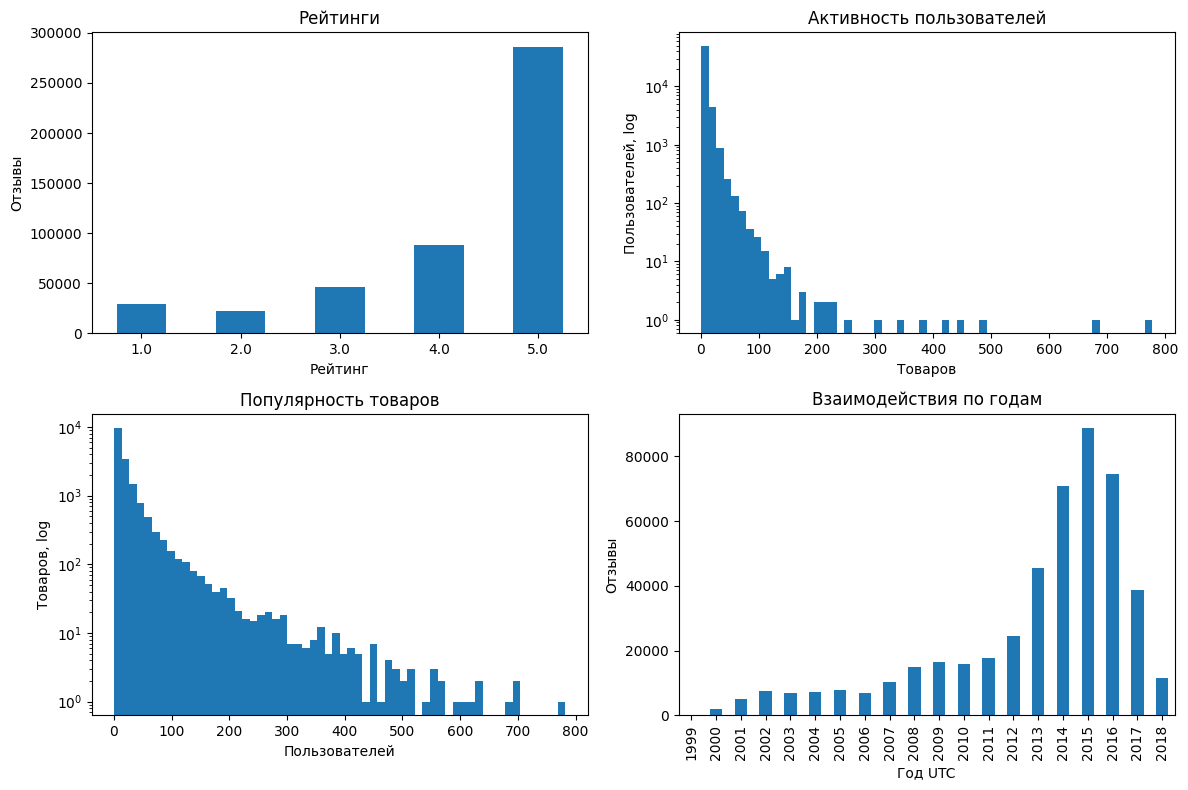

,user_activity,item_popularity
count,55223.000000,17389.000000
mean,8.560618,27.186325
std,10.077472,47.367199
min,1.000000,1.000000
50%,6.000000,12.000000
90%,14.000000,58.000000
99%,41.000000,251.000000
max,777.000000,782.000000


Доля рейтингов >=4: 0.7920878786148077
Временной диапазон: 1999-10-14 00:00:00+00:00 — 2018-10-02 00:00:00+00:00
Разреженность: 0.999507699243286


,top_items_pct,interaction_share_pct
0,1.0,13.430976
1,5.0,34.868417
2,10.0,48.444292


In [7]:
user_activity = reviews_clean.groupby("reviewerID").asin.nunique()
item_popularity = reviews_clean.groupby("asin").reviewerID.nunique()
clean_dates = pd.to_datetime(reviews_clean.unixReviewTime, unit="s", utc=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
reviews_clean.overall.value_counts().sort_index().plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Рейтинги", xlabel="Рейтинг", ylabel="Отзывы")
user_activity.plot.hist(bins=60, logy=True, ax=axes[0, 1])
axes[0, 1].set(
    title="Активность пользователей", xlabel="Товаров", ylabel="Пользователей, log"
)
item_popularity.plot.hist(bins=60, logy=True, ax=axes[1, 0])
axes[1, 0].set(
    title="Популярность товаров", xlabel="Пользователей", ylabel="Товаров, log"
)
clean_dates.dt.year.value_counts().sort_index().plot.bar(ax=axes[1, 1])
axes[1, 1].set(title="Взаимодействия по годам", xlabel="Год UTC", ylabel="Отзывы")
plt.tight_layout()
plt.show()
display(
    pd.DataFrame(
        {
            "user_activity": user_activity.describe(percentiles=[0.5, 0.9, 0.99]),
            "item_popularity": item_popularity.describe(percentiles=[0.5, 0.9, 0.99]),
        }
    )
)
print("Доля рейтингов >=4:", reviews_clean.overall.ge(4).mean())
print("Временной диапазон:", clean_dates.min(), "—", clean_dates.max())
print(
    "Разреженность:",
    1 - len(reviews_clean) / (len(user_activity) * len(item_popularity)),
)

popular = item_popularity.sort_values(ascending=False)
concentration = []
for fraction in [0.01, 0.05, 0.10]:
    count = int(np.ceil(len(popular) * fraction))
    concentration.append(
        {
            "top_items_pct": fraction * 100,
            "interaction_share_pct": 100
            * popular.iloc[:count].sum()
            / len(reviews_clean),
        }
    )
display(pd.DataFrame(concentration))

Рейтинги >=4 составляют 79,21%. Медианная история пользователя — 6 товаров; у 4357 пользователей осталось менее 5 уникальных товаров. Верхние 10% товаров получают 48,44% взаимодействий. Разреженность — 99,95077%. Эти глобальные статистики используются только для EDA, не для отбора каталога или обучения признаков.

### Метаданные

In [8]:
STOPWORDS = set(
    (
        "a an the and or but if to of in on at for with by from as is are was were "
        "be been being it its this that these those i you we they he she my your "
        "our their not no so than then can could would should will have has had "
        "do does did into about more most very also"
    ).split()
)


def text(value):
    if isinstance(value, list):
        value = " ".join(str(v) for v in value)
    if not isinstance(value, str):
        return ""
    return " ".join(re.sub(r"<[^>]*>", " ", html.unescape(value)).lower().split())


def brand(value):
    return re.sub(r"^by\s+", "", text(value)) or "<UNK>"


def tokens(value):
    return [
        s
        for s in re.findall(r"[a-z0-9]+", text(value))
        if len(s) > 1 and s not in STOPWORDS
    ]

In [9]:
display(
    pd.Series(
        {
            col: metadata_used[col].map(is_absent).mean() * 100
            for col in ["title", "brand", "category", "description"]
        },
        name="absent_pct",
    ).to_frame()
)
brands = metadata_used.brand.map(brand)
category_level2 = metadata_used.category.map(
    lambda values: (
        text(values[1]) if isinstance(values, list) and len(values) > 1 else "<UNK>"
    )
)
display(brands.value_counts().head(10).to_frame("items"))
display(category_level2.value_counts().head(10).to_frame("items"))
display(
    metadata_used.description.map(lambda value: len(text(value)))
    .describe()
    .to_frame("description_length")
)

,absent_pct
title,0.000000
brand,0.690091
category,0.874116
description,3.157168


,items
brand,
electronic arts,1249
nintendo,1084
activision,1044
ubisoft,775
sony,682
microsoft,549
sega,501
thq,370
capcom,367


,items
category,
retro gaming & microconsoles,4299
pc,3899
kids & family,2668
xbox 360,1316
playstation 3,1185
playstation 4,796
xbox one,680
wii,652
nintendo 3ds & 2ds,416


,description_length
count,17389.000000
mean,1162.485307
std,1432.174698
min,0.000000
25%,299.000000
50%,659.000000
75%,1472.000000
max,15438.000000


Бренд отсутствует примерно у 0,69% очищенных товаров, категории — у 0,87%, описание — у 3,16%. Второй уровень category содержит и платформы, и общие разделы (например, Kids & Family); используем его как категорию, не называем платформой. Метаданные недатированные: их историческая доступность остаётся предположением.

## 3. Протокол оценки

- Глобальное временное разбиение **70/20/10** до warm-start фильтрации. Одинаковые timestamps не разделяются.
- Каталог — **все первоначальные train-товары**, без отбора по популярности. ID-словари строятся только по train.
- В validation/test оставляем известных пользователей и товары. Когорты с хотя бы одним релевантным отложенным событием общие для моделей.
- При validation исключаем все известные train-товары; при test — train+validation, включая низкие оценки. Кандидаты — полный допустимый каталог, без negative sampling.
- Параметры выбираются по validation. Затем все модели заново обучаются на **train+validation**, сохраняя каталог. Test используется после фиксации настроек.
- Для timeSVD++ время запроса — начало соответствующего периода. Даты отдельных отложенных отзывов при вычислении прогнозов не используются.

Основная метрика — **NDCG@10** (порядок в десятке), дополнительная — **Recall@10** (охват релевантных товаров). Релевантность: rating>=4. Усредняем по пользователям.

$$Recall@10(u)=\frac{|R_u\cap L_u^{10}|}{|R_u|},\qquad
NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbf{1}[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

При равных прогнозах товары упорядочиваются по `item_idx` — лексикографическому порядку ASIN.

In [10]:
def prepare(reviews, metadata):
    frame, meta = clean(reviews, metadata)
    t1, t2 = frame.unixReviewTime.quantile([0.7, 0.9], interpolation="lower")
    raw = [
        frame.loc[frame.unixReviewTime <= t1].copy(),
        frame.loc[(frame.unixReviewTime > t1) & (frame.unixReviewTime <= t2)].copy(),
        frame.loc[frame.unixReviewTime > t2].copy(),
    ]
    users, items = sorted(raw[0].reviewerID.unique()), sorted(raw[0].asin.unique())
    umap = {u: i for i, u in enumerate(users)}
    imap = {item: i for i, item in enumerate(items)}
    splits = [raw[0]] + [
        p.loc[p.reviewerID.isin(users) & p.asin.isin(items)].copy() for p in raw[1:]
    ]
    for part in splits:
        part["user_idx"] = part.reviewerID.map(umap).astype("int64")
        part["item_idx"] = part.asin.map(imap).astype("int64")
        part.sort_values(
            ["unixReviewTime", "user_idx", "item_idx"], kind="stable", inplace=True
        )
        part.reset_index(drop=True, inplace=True)
    if not (
        100000 <= sum(map(len, splits)) <= 2000000
        and min(len(users), len(items)) >= 1000
    ):
        raise ValueError("Prepared sample violates homework size requirements")
    assert splits[0].unixReviewTime.max() < splits[1].unixReviewTime.min()
    assert splits[1].unixReviewTime.max() < splits[2].unixReviewTime.min()
    report = {
        "cleaned_rows": len(frame),
        "raw_split_rows": list(map(len, raw)),
        "prepared_split_rows": list(map(len, splits)),
        "excluded_cold_start_rows": [len(a) - len(b) for a, b in zip(raw, splits)],
        "cutoffs_unix": [int(t1), int(t2)],
        "n_users": len(users),
        "n_items": len(items),
        "catalogue": "all training items; no popularity selection",
        "user_mapping": umap,
        "item_mapping": imap,
    }
    return splits, meta.loc[meta.asin.isin(items)].copy(), report


def save(splits, meta, report, data_dir="data"):
    out = Path(data_dir) / "processed"
    out.mkdir(parents=True, exist_ok=True)
    for name, part in zip(["train", "validation", "test"], splits):
        part.to_csv(
            out / f"{name}.csv.gz",
            index=False,
            compression={"method": "gzip", "mtime": 0},
        )
    meta.to_json(out / "item_metadata.jsonl", orient="records", lines=True)
    (out / "preparation.json").write_text(json.dumps(report, indent=2))

In [11]:
splits, model_metadata, preparation = prepare(reviews, metadata)
save(splits, model_metadata, preparation, DATA)
train, validation, test_audit = splits
summary = []
for name, part, raw_rows in zip(
    ["train", "validation", "test"], splits, preparation["raw_split_rows"]
):
    summary.append(
        {
            "split": name,
            "raw_rows": raw_rows,
            "warm_rows": len(part),
            "excluded_rows": raw_rows - len(part),
            "users": part.reviewerID.nunique(),
            "items": part.asin.nunique(),
        }
    )
display(pd.DataFrame(summary))
print(
    "Границы UTC:",
    pd.to_datetime(preparation["cutoffs_unix"], unit="s", utc=True).tolist(),
)
assert 100_000 <= sum(map(len, splits)) <= 2_000_000
assert preparation["n_users"] >= 1000 and preparation["n_items"] >= 1000
del splits, test_audit

,split,raw_rows,warm_rows,excluded_rows,users,items
0,train,331015,331015,0,46429,15705
1,validation,94557,35348,59209,13132,8388
2,test,47171,12768,34403,6041,5085


Границы UTC: [Timestamp('2015-10-22 00:00:00+0000', tz='UTC'), Timestamp('2017-01-15 00:00:00+0000', tz='UTC')]


В warm-start выборке 379 131 событие и 15 705 товаров. Исключены 59 209 validation- и 34 403 test-события; поэтому итоговые доли отличаются от 70/20/10. Это существенная потеря покрытия: выводы не относятся к cold-start.

## 4. Обучение моделей

ItemKNN, Explicit ALS, FM и timeSVD++ обучаются на оценках 1–5. SLIM использует бинарные положительные взаимодействия с оценкой ≥4. Обучающие сигналы различаются, но критерий релевантности, пользователи, кандидаты и правила оценки одинаковы для всех моделей.

In [12]:
from models.item_knn import ItemKNN
from models.als import ExplicitALS
from models.slim import SLIM
from models.fm import FM
from models.time_svdpp import TimeSVDpp

### ItemKNN: Pearson

Корреляция считается по общим пользователям U_ij; средние товаров вычисляются на этом пересечении:

$$s(i,j)=\frac{\sum_{u\in U_{ij}}(r_{ui}-\bar r_i)(r_{uj}-\bar r_j)}{\sqrt{\sum_{u\in U_{ij}}(r_{ui}-\bar r_i)^2\sum_{u\in U_{ij}}(r_{uj}-\bar r_j)^2}}.$$

$$\hat r_{ui}=\bar r_u+
\frac{\sum_{j\in I_u\cap N_k(i)}s(i,j)(r_{uj}-\bar r_u)}{\sum_{j\in I_u\cap N_k(i)}|s(i,j)|}.$$

N_k(i) — соседи с наибольшим модулем корреляции. Пара товаров должна иметь не менее `min_common` общих оценок. При нулевой дисперсии сходство равно нулю, при отсутствии подходящих соседей прогноз равен среднему рейтингу пользователя.

### Explicit ALS

Обозначения лекции: x_i — пользователь, y_j — товар.

$$\min_{X,Y}\sum_{(i,j)\in R}(r_{ij}-x_i^Ty_j)^2+\lambda\sum_i\|x_i\|^2+\lambda\sum_j\|y_j\|^2.$$

$$x_i=\left(\sum_{j:(i,j)\in R}y_jy_j^T+\lambda I\right)^{-1}\sum_{j:(i,j)\in R}r_{ij}y_j.$$

Обновления чередуются; системы решаются через `np.linalg.solve`. Это вариант C_i=C_j=1 общей формулы. Ошибка считается только по наблюдаемым оценкам.

### SLIM

A — бинарные положительные взаимодействия:

$$\hat a_{ui}=\sum_jw_{ij}a_{uj},\qquad W\ge0,\quad w_{ii}=0,$$
$$\min_W\frac12\sum_{u,i}\left(a_{ui}-\sum_jw_{ij}a_{uj}\right)^2
+\lambda\sum_{i,j}|w_{ij}|+\frac\beta2\sum_{i,j}w_{ij}^2.$$

В коде B=W^T, `l1`=lambda, `l2`=beta. Обучение — собственный координатный спуск. По условиям KKT координаты с G_ij<=l1 имеют нулевой вес и пропускаются; каталог сохраняется полностью. Точность — 1e-5, до 500 проходов; сходимость проверяется для каждого товара.

### FM

$$a(x)=w_0+\sum_iw_ix_i+\sum_i\sum_{j>i}\langle v_i,v_j\rangle x_ix_j.$$

В коде парные взаимодействия считаются как
$$\frac12\left(\left\|\sum_i v_ix_i\right\|^2-\sum_i\|v_i\|^2x_i^2\right).$$

Признаки: user/item ID, бренд, второй уровень категории и TF-IDF описания. Словарь — до 2000 слов с df>=3 и df<=80% train-товаров; TF=1+log(count), IDF=log((1+n)/(1+df))+1. Для товара оставляем до 20 слов и нормируем TF-IDF по L2. Пустые категории — UNK; неизвестные слова игнорируются.

Обучение: MSE + lambda·E[sum x_i²(w_i²+||v_i||²)]. Словари строятся по текущей обучающей истории. Контрольные варианты: только ID и ID+бренд+категория, с настройками полной FM.

### timeSVD++

$$\hat r_{ui}(t)=\mu+b_i+b_{i,bin(t)}+b_u+\alpha_u dev_u(t)+b_{u,t}
+q_i^T\left(p_u+\alpha_u^p dev_u(t)+p_{u,t}+\frac{\sum_{j\in N(u)}y_j}{\sqrt{|N(u)|}}\right),$$
$$dev_u(t)=sign(t-\bar t_u)\left|\frac{t-\bar t_u}{365}\right|^{0.4}.$$

Время измеряется в днях UTC; используются 30 временных интервалов. N(u) — товары текущей обучающей истории, включая низкие оценки. Для неизвестных дней персональные поправки равны нулю. Будущие даты относятся к последнему интервалу товара; временной тренд экстраполируется. Обучение: MSE + lambda·||theta||²/|R|, кроме глобального среднего. Временные статистики и история строятся только по обучающим данным.

### Подбор параметров

Выбираем максимальный NDCG@10 на validation. При равенстве оставляем первую конфигурацию. Для FM дополнительно сравниваем наборы признаков при настройках полной модели. Популярность — неперсональный ориентир; она считается только по положительным обучающим отзывам.

### Подготовка признаков FM

Для каждой пары формируем индексы признаков и их веса. ID, бренд и категория имеют вес 1; слова описания — вес TF-IDF. Индекс 0 обозначает заполнение пустых позиций. Словари строятся только по товарам текущей обучающей истории.

In [13]:
class ItemFeatures:
    def __init__(
        self,
        include_metadata=True,
        include_text=True,
        max_vocab=2000,
        max_tokens=20,
        min_df=3,
    ):
        self.include_metadata = include_metadata
        self.include_text = include_text
        self.max_vocab = max_vocab
        self.max_tokens = max_tokens
        self.min_df = min_df

    def fit(self, train, metadata, n_users, n_items):
        self.n_users = n_users
        meta = metadata.drop_duplicates("asin").set_index("asin")
        item_rows = (
            train[["item_idx", "asin"]].drop_duplicates().sort_values("item_idx")
        )
        records = [{} for _ in range(n_items)]
        for row in item_rows.itertuples():
            if row.asin in meta.index:
                records[row.item_idx] = meta.loc[row.asin].to_dict()
        fields = [[1 + n_users + i] for i in range(n_items)]
        weights = [[1.0] for _ in range(n_items)]
        next_id = 1 + n_users + n_items
        self.vocabularies = {}
        if self.include_metadata:
            brands = [brand(r.get("brand")) for r in records]
            categories = []
            for r in records:
                values = r.get("category")
                categories.append(
                    (
                        text(values[1])
                        if isinstance(values, list) and len(values) > 1
                        else ""
                    )
                    or "<UNK>"
                )
            for name, values in [("brand", brands), ("category_level2", categories)]:
                vocab = {
                    v: next_id + j
                    for j, v in enumerate(sorted(set(values) | {"<UNK>"}))
                }
                self.vocabularies[name] = vocab
                next_id += len(vocab)
                for i, v in enumerate(values):
                    fields[i].append(vocab[v])
                    weights[i].append(1.0)
        self.text_vocabulary = {}
        self.idf = {}
        if self.include_text:
            documents = [tokens(r.get("description")) for r in records]
            df = Counter()
            for document in documents:
                df.update(set(document))
            selected = [t for t in df if self.min_df <= df[t] <= 0.8 * n_items]
            selected = sorted(selected, key=lambda t: (-df[t], t))[: self.max_vocab]
            self.text_vocabulary = {t: next_id + j for j, t in enumerate(selected)}
            self.idf = {
                t: float(np.log((1 + n_items) / (1 + df[t])) + 1) for t in selected
            }
            next_id += len(selected)
            for i, document in enumerate(documents):
                counts = Counter(document)
                tfidf = [
                    (t, (1 + np.log(count)) * self.idf[t])
                    for t, count in counts.items()
                    if t in self.text_vocabulary
                ]
                tfidf = sorted(tfidf, key=lambda p: (-p[1], p[0]))[: self.max_tokens]
                norm = np.sqrt(sum(w * w for _, w in tfidf)) or 1.0
                for token, w in tfidf:
                    fields[i].append(self.text_vocabulary[token])
                    weights[i].append(float(w / norm))
        width = max(map(len, fields))
        self.item_fields = np.zeros((n_items, width), dtype=np.int64)
        self.item_weights = np.zeros((n_items, width), dtype=np.float32)
        for i, (f, w) in enumerate(zip(fields, weights)):
            self.item_fields[i, : len(f)] = f
            self.item_weights[i, : len(w)] = w
        self.n_features = next_id
        return self

    def transform(self, users, items):
        users = np.asarray(users, dtype=np.int64)
        items = np.asarray(items, dtype=np.int64)
        fields = np.column_stack([1 + users, self.item_fields[items]])
        weights = np.column_stack(
            [np.ones(len(users), dtype=np.float32), self.item_weights[items]]
        )
        return fields, weights

In [14]:
def fit_model(model, history, n_users, n_items, metadata=None):
    if isinstance(model, FM):
        features = ItemFeatures(
            include_metadata=model.include_metadata,
            include_text=model.include_text,
        ).fit(history, metadata, n_users, n_items)
        return model.fit(history, n_users, n_items, features=features)
    return model.fit(history, n_users, n_items, metadata)

### Метрики и исключение известных товаров

Сначала фиксируем релевантные товары для каждого пользователя. Затем получаем оценки полного каталога, исключаем известные товары и выбираем top-10. Считаем небольшими пакетами пользователей, чтобы не хранить всю матрицу прогнозов.

In [15]:
def interactions(frame, n_users, n_items, positive=False):
    rows = frame[frame.overall >= 4] if positive else frame
    return csr_matrix(
        (np.ones(len(rows)), (rows.user_idx, rows.item_idx)),
        shape=(n_users, n_items),
        dtype=np.float64,
    )


def cohort(holdout, known, n_items):
    if n_items < 1 or not holdout.item_idx.between(0, n_items - 1).all():
        raise ValueError("Holdout item outside candidate catalogue")
    relevant = holdout[holdout.overall >= 4]
    seen = set(zip(known.user_idx, known.item_idx))
    truth = {}
    for row in relevant.itertuples():
        if (row.user_idx, row.item_idx) not in seen:
            truth.setdefault(int(row.user_idx), set()).add(int(row.item_idx))
    if not truth:
        raise ValueError("Empty evaluation cohort")
    return dict(sorted(truth.items()))


def topk(scores, known, k=10):
    scores = np.array(scores, dtype=float, copy=True)
    if scores.ndim != 2 or scores.shape != known.shape:
        raise ValueError("Scores and known-item mask must have the same 2D shape")
    if not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("K must be a positive integer")
    if not np.isfinite(scores).all():
        raise ValueError("Nonfinite predictions")
    rows, cols = known.nonzero()
    scores[rows, cols] = -np.inf
    if (np.isfinite(scores).sum(axis=1) < k).any():
        raise ValueError("Fewer than K eligible candidates")
    return np.argsort(-scores, axis=1, kind="stable")[:, :k]


def ranking_metrics(recommendations, relevant, k=10):
    recommendations = np.asarray(recommendations)
    relevant = list(relevant)
    if not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("K must be a positive integer")
    if (
        recommendations.ndim != 2
        or recommendations.shape != (len(relevant), k)
        or not relevant
    ):
        raise ValueError("Expected one K-item recommendation list per user")
    if any(not truth for truth in relevant):
        raise ValueError("Each evaluated user needs relevant items")
    if any(len(set(row)) != k for row in recommendations):
        raise ValueError("Recommendations must contain unique items")
    recalls, ndcgs = [], []
    discount = 1 / np.log2(np.arange(2, k + 2))
    for recs, truth in zip(recommendations, relevant):
        hit = np.array([item in truth for item in recs], dtype=float)
        recalls.append(hit.sum() / len(truth))
        ndcgs.append(float(hit @ discount) / discount[: min(k, len(truth))].sum())
    return {f"NDCG@{k}": float(np.mean(ndcgs)), f"Recall@{k}": float(np.mean(recalls))}


def evaluate(model, truth, known, n_users, n_items, when, batch_size=64):
    if not truth or batch_size < 1:
        raise ValueError("Evaluation needs users and positive batch size")
    if any(
        u < 0 or u >= n_users or not items or any(i < 0 or i >= n_items for i in items)
        for u, items in truth.items()
    ):
        raise ValueError("Invalid evaluation user or relevant item")
    known_matrix = interactions(known, n_users, n_items)
    users = np.array(sorted(truth))
    sums = {"NDCG@10": 0.0, "Recall@10": 0.0}
    for start in range(0, len(users), batch_size):
        batch = users[start : start + batch_size]
        scores = predict(model, batch, when)
        recs = topk(scores, known_matrix[batch])
        metrics = ranking_metrics(recs, [truth[u] for u in batch])
        for key in sums:
            sums[key] += metrics[key] * len(batch)
    return {**{k: v / len(users) for k, v in sums.items()}, "users": len(users)}

### Пространство поиска

In [16]:
SEED = 42


GRIDS = {
    "ItemKNN": {"neighbors": [40, 100], "min_common": [3, 5]},
    "ExplicitALS": {
        "rank": [8, 16],
        "regularization": [1.0, 10.0],
        "iterations": [8],
        "seed": [SEED],
    },
    "SLIM": {"l1": [1.0, 3.0], "l2": [5.0, 20.0]},
    "FM": {
        "rank": [8, 16],
        "regularization": [1e-4, 1e-3],
        "learning_rate": [0.01],
        "epochs": [8],
        "seed": [SEED],
    },
    "timeSVD++": {
        "rank": [8, 16],
        "regularization": [1.0, 10.0],
        "learning_rate": [0.005],
        "epochs": [8],
        "n_bins": [30],
        "beta": [0.4],
        "seed": [SEED],
    },
}


MODEL_CLASSES = {
    "ItemKNN": ItemKNN,
    "ExplicitALS": ExplicitALS,
    "SLIM": SLIM,
    "FM": FM,
    "timeSVD++": TimeSVDpp,
}


FM_ABLATIONS = {
    "FM_ID_only": {"include_metadata": False, "include_text": False},
    "FM_no_text": {"include_metadata": True, "include_text": False},
}

In [17]:
def configurations(grid):
    return [dict(zip(grid, values)) for values in itertools.product(*grid.values())]


def make_model(name, parameters):
    if name == "Popularity":
        return Popularity()
    model_class = FM if name in FM_ABLATIONS else MODEL_CLASSES[name]
    return model_class(**parameters)


def predict(model, users, when):
    if isinstance(model, TimeSVDpp):
        return model.score(users, when=when)
    return model.score(users)


class Popularity:
    def fit(self, frame, n_users, n_items, metadata=None):
        positive = interactions(frame, n_users, n_items, positive=True)
        self.counts = np.asarray(positive.sum(axis=0)).ravel()
        return self

    def score(self, users):
        return np.broadcast_to(self.counts, (len(users), len(self.counts)))

### Проверка метрик

На примере с двумя релевантными товарами проверяем Recall и NDCG. Отдельно проверяем исключение уже известных товаров.

In [18]:
example = ranking_metrics(np.arange(10)[None, :], [{1, 15}])
assert np.isclose(example["Recall@10"], 0.5)
assert np.isclose(example["NDCG@10"], (1 / np.log2(3)) / (1 + 1 / np.log2(3)))
mask = csr_matrix(([1.0], ([0], [0])), shape=(1, 20))
recommendations = topk(np.zeros((1, 20)), mask)
assert recommendations.tolist() == [list(range(1, 11))]
assert brand("by\n Nintendo") == "nintendo"
assert tokens("<b>Space</b> &amp; adventure") == ["space", "adventure"]

### Подбор на validation

Каждую конфигурацию обучаем с нуля на train. Словарь FM строим заново по этой же истории. Test на этом шаге не используется.

In [19]:
n_users, n_items = preparation["n_users"], preparation["n_items"]
validation_time, test_time = [t + 86400 for t in preparation["cutoffs_unix"]]
validation_truth = cohort(validation, train, n_items)


def validate_configuration(name, parameters):
    start = time.perf_counter()
    model = fit_model(
        make_model(name, parameters), train, n_users, n_items, model_metadata
    )
    fit_seconds = time.perf_counter() - start
    metrics = evaluate(
        model, validation_truth, train, n_users, n_items, validation_time
    )
    row = {
        "model": name,
        "params": json.dumps(parameters, sort_keys=True),
        **metrics,
        "fit_seconds": fit_seconds,
        "loss_history": json.dumps(getattr(model, "loss_history", [])),
    }
    print(name, parameters, metrics, flush=True)
    del model
    gc.collect()
    return row


validation_rows, selected = [], {}
for name, grid in GRIDS.items():
    rows = [validate_configuration(name, params) for params in configurations(grid)]
    validation_rows.extend(rows)
    best = max(rows, key=lambda row: row["NDCG@10"])
    selected[name] = json.loads(best["params"])

for name, flags in FM_ABLATIONS.items():
    selected[name] = {**selected["FM"], **flags}
    validation_rows.append(validate_configuration(name, selected[name]))

validation_rows.append(validate_configuration("Popularity", {}))
validation_results = pd.DataFrame(validation_rows)
display(validation_results[["model", "params", "NDCG@10", "Recall@10", "fit_seconds"]])

ItemKNN {'neighbors': 40, 'min_common': 3} {'NDCG@10': 0.0025022057047593164, 'Recall@10': 0.00434193442142663, 'users': 11313}
ItemKNN {'neighbors': 40, 'min_common': 5} {'NDCG@10': 0.0036084965011945465, 'Recall@10': 0.005919135025612438, 'users': 11313}
ItemKNN {'neighbors': 100, 'min_common': 3} {'NDCG@10': 0.002748803976178933, 'Recall@10': 0.004712530896735268, 'users': 11313}
ItemKNN {'neighbors': 100, 'min_common': 5} {'NDCG@10': 0.0032287103839729854, 'Recall@10': 0.005239117479652014, 'users': 11313}
ExplicitALS {'rank': 8, 'regularization': 1.0, 'iterations': 8, 'seed': 42} {'NDCG@10': 0.0018611771014738203, 'Recall@10': 0.003362974134548058, 'users': 11313}
ExplicitALS {'rank': 8, 'regularization': 10.0, 'iterations': 8, 'seed': 42} {'NDCG@10': 0.008406632549072804, 'Recall@10': 0.013603102992884853, 'users': 11313}
ExplicitALS {'rank': 16, 'regularization': 1.0, 'iterations': 8, 'seed': 42} {'NDCG@10': 0.0025055349604924675, 'Recall@10': 0.0040267803703673945, 'users': 113

,model,params,NDCG@10,Recall@10,fit_seconds
0,ItemKNN,"{""min_common"": 3, ""neighbors"": 40}",0.002502,0.004342,0.835758
1,ItemKNN,"{""min_common"": 5, ""neighbors"": 40}",0.003608,0.005919,0.740965
2,ItemKNN,"{""min_common"": 3, ""neighbors"": 100}",0.002749,0.004713,0.854848
3,ItemKNN,"{""min_common"": 5, ""neighbors"": 100}",0.003229,0.005239,0.721188
4,ExplicitALS,"{""iterations"": 8, ""rank"": 8, ""regularization"":...",0.001861,0.003363,4.862694
5,ExplicitALS,"{""iterations"": 8, ""rank"": 8, ""regularization"":...",0.008407,0.013603,4.807966
6,ExplicitALS,"{""iterations"": 8, ""rank"": 16, ""regularization""...",0.002506,0.004027,5.526919
7,ExplicitALS,"{""iterations"": 8, ""rank"": 16, ""regularization""...",0.008894,0.014829,5.543976
8,SLIM,"{""l1"": 1.0, ""l2"": 5.0}",0.022036,0.033486,51.349125
9,SLIM,"{""l1"": 1.0, ""l2"": 20.0}",0.022660,0.034724,50.841863


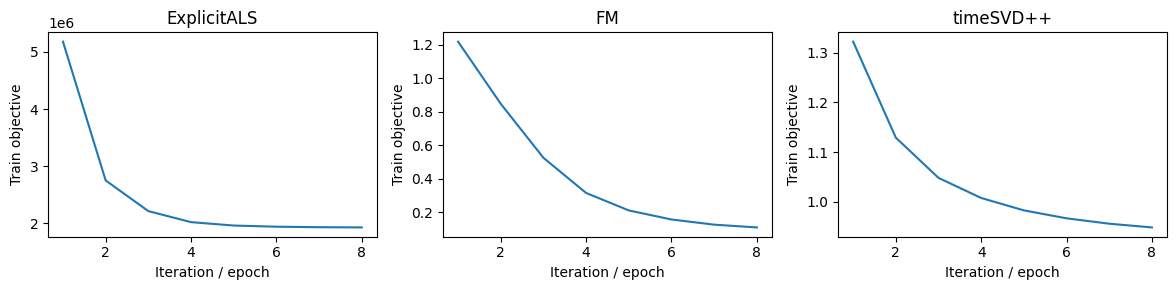

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for name, ax in zip(["ExplicitALS", "FM", "timeSVD++"], axes):
    group = validation_results.loc[validation_results.model.eq(name)]
    best_row = group.loc[group["NDCG@10"].idxmax()]
    history = json.loads(best_row.loss_history)
    ax.plot(range(1, len(history) + 1), history)
    ax.set(title=name, xlabel="Iteration / epoch", ylabel="Train objective")
plt.tight_layout()
plt.show()

### Переобучение на train + validation

Настройки выбраны. Обучаем все модели заново, включая словари FM и временные статистики timeSVD++. Каталог и индексы остаются прежними.

In [21]:
history = pd.concat([train, validation], ignore_index=True).sort_values(
    ["unixReviewTime", "user_idx", "item_idx"], kind="stable"
)
models = {}
for name, parameters in selected.items():
    model = fit_model(
        make_model(name, parameters), history, n_users, n_items, model_metadata
    )
    models[name] = model
    print("Обучена:", name, flush=True)

models["Popularity"] = Popularity().fit(history, n_users, n_items)
print("Событий финального обучения:", len(history))

Обучена: ItemKNN
Обучена: ExplicitALS
Обучена: SLIM
Обучена: FM
Обучена: timeSVD++
Обучена: FM_ID_only
Обучена: FM_no_text
Событий финального обучения: 366363


### Финальная оценка

Считаем test один раз после выбора настроек. Для всех моделей используем одних пользователей, полный каталог и одинаковую маску train+validation.

In [22]:
test = pd.read_csv(DATA / "processed/test.csv.gz", keep_default_na=False)
test_truth = cohort(test, history, n_items)
result_rows = []
for name, model in models.items():
    metrics = evaluate(model, test_truth, history, n_users, n_items, test_time)
    result_rows.append(
        {
            "model": name,
            **metrics,
            "params": json.dumps(selected.get(name, {}), sort_keys=True),
        }
    )
final_results = pd.DataFrame(result_rows)

## 5. Сравнительный анализ

Test оценивается один раз после фиксации настроек и refit. Все модели используют одинаковые когорты, кандидатов и маски известных товаров. Popularity и абляции FM — дополнительные контрольные варианты.

,model,NDCG@10,Recall@10,users,params
0,SLIM,0.020341,0.033601,4940,"{""l1"": 1.0, ""l2"": 20.0}"
1,ExplicitALS,0.008953,0.017074,4940,"{""iterations"": 8, ""rank"": 16, ""regularization""..."
2,Popularity,0.007120,0.014454,4940,{}
3,timeSVD++,0.005232,0.008810,4940,"{""beta"": 0.4, ""epochs"": 8, ""learning_rate"": 0...."
4,ItemKNN,0.003925,0.006872,4940,"{""min_common"": 5, ""neighbors"": 40}"
5,FM_ID_only,0.001406,0.002865,4940,"{""epochs"": 8, ""include_metadata"": false, ""incl..."
6,FM,0.000951,0.001677,4940,"{""epochs"": 8, ""learning_rate"": 0.01, ""rank"": 1..."
7,FM_no_text,0.000852,0.001687,4940,"{""epochs"": 8, ""include_metadata"": true, ""inclu..."


Пользователей validation / test: 11313 4940
Событий финального обучения: 366363


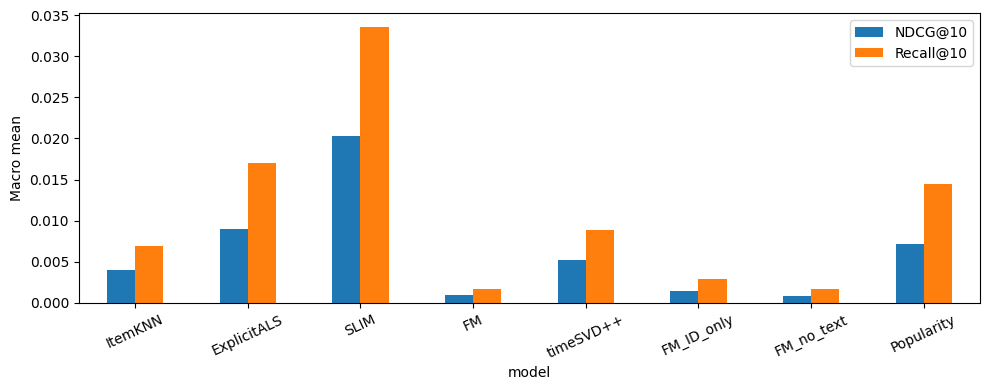

In [23]:
required = ["ItemKNN", "ExplicitALS", "SLIM", "FM", "timeSVD++"]
display(final_results.sort_values("NDCG@10", ascending=False).reset_index(drop=True))
print(
    "Пользователей validation / test:",
    len(validation_truth),
    len(test_truth),
)
print("Событий финального обучения:", len(history))
final_results.set_index("model")[["NDCG@10", "Recall@10"]].plot.bar(
    figsize=(10, 4), rot=25
)
plt.ylabel("Macro mean")
plt.tight_layout()
plt.show()

### Пример рекомендаций

Первые три пользователя общей test-сплита. Уже известные товары исключены - ниже показана десятка лучшей модели для первого пользователя.

In [24]:
example_users = np.array(sorted(test_truth)[:3])
known = interactions(history, n_users, n_items)
examples = {
    "user_idx": example_users.tolist(),
    "top10_item_idx": {
        name: topk(
            predict(model, example_users, test_time), known[example_users]
        ).tolist()
        for name, model in models.items()
    },
}

In [25]:
table = final_results.set_index("model")
winner = table.loc[required, "NDCG@10"].idxmax()
recommendations = examples["top10_item_idx"][winner][0]
item_asin = (
    train[["item_idx", "asin"]].drop_duplicates().set_index("item_idx").asin.to_dict()
)
titles = metadata_clean.set_index("asin").title.to_dict()
print(winner, "user_idx:", examples["user_idx"][0])
display(
    pd.DataFrame(
        {
            "rank": range(1, 11),
            "asin": [item_asin[i] for i in recommendations],
            "title": [titles.get(item_asin[i], "<UNK>") for i in recommendations],
        }
    )
)

SLIM user_idx: 0


,rank,asin,title
0,1,B00008KTRS,Shin Megami Tensei: Digital Devil Saga - PlayS...
1,2,B000TLU67W,PlayStation 2 Console Slim PS2
2,3,B012JIOKM4,World of Warcraft 60 Day Game Time [Digital Co...
3,4,B000784XG2,Shin Megami Tensei Digital Devil Saga 2 - Play...
4,5,B0014CN2H6,Shin Megami Tensei: Persona 3 FES - PlayStation 2
5,6,B000FPM4WC,Shin Megami Tensei: Persona 3 - PlayStation 2
6,7,B00005T7ZN,Shadow Hearts
7,8,B00GLZQR96,Diablo III: Ultimate Evil Edition
8,9,B002CZ38KA,Heavy Rain - Greatest Hits
9,10,B002VA593A,Shin Megami Tensei: Strange Journey - Nintendo DS


## 6. Выводы

**Лучший результат показал SLIM** при `l1=1, l2=20`:
NDCG@10 = 0,02034, Recall@10 = 0,03360.
Он опередил остальные методы по обеим метрикам. Его NDCG
примерно в 2,27 раза выше, чем у Explicit ALS — второго
по качеству метода.

**Персонализация помогла не всем моделям.** SLIM и Explicit ALS
превзошли Popularity, тогда как ItemKNN, FM и timeSVD++
уступили этому неперсональному ориентиру. В выбранных настройках
сложность модели сама по себе не обеспечила лучшего ранжирования.

**Метаданные не улучшили FM относительно варианта только с ID:**
NDCG@10 составил 0,00095 против 0,00141. Добавление описания
к бренду и категории повысило NDCG примерно на 0,00010,
но не улучшило Recall. Это результат выбранного набора признаков
и настроек, а не доказательство бесполезности метаданных.

**timeSVD++ уступил Explicit ALS:** NDCG@10 — 0,00523
против 0,00895. Поскольку временные компоненты отдельно
не отключались, оценить именно их вклад по этому сравнению нельзя.

**Ограничения.** Использованы одно временное разбиение, один seed
и небольшой набор конфигураций. Оценка охватывает только известных
пользователей и товары; значительная часть отложенных событий
исключена из-за cold-start. Историческая доступность метаданных
не подтверждена, статистическая значимость различий не проверялась.
Поэтому преимущество SLIM относится к проведённому эксперименту.